# Encuesta Anual de Comercio (EAC) 2024 — DANE
### Proyecto DataXperience · Universidad EAN

**Integrantes:** Stiven Melo, _(pendiente)_, _(pendiente)_

**Fuente:** DANE — Encuesta Anual de Comercio (EAC), año de referencia 2024.
<https://www.dane.gov.co/index.php/estadisticas-por-tema/comercio-interno/encuesta-anual-de-comercio-eac>

**Unidad de observación:** la empresa comercial (microdato anonimizado).
**Unidad monetaria:** miles de pesos corrientes.

---


---
# Bloque A — Configuración

In [ ]:
# C01 — Importar librerías y fijar opciones de visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option("display.float_format", "{:,.1f}".format)
sns.set_theme(style="whitegrid")

print("pandas:", pd.__version__, "|numpy:", np.__version__, "| seaborn:", sns.__version__)

pandas: 3.1.0 |numpy: 2.5.4 | seaborn: 0.13.2


In [ ]:
# C02 — Definir las rutas del proyecto
RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
CRUDOS = RAIZ / "datos" / "crudos"
PROCESADOS = RAIZ / "datos" / "procesados"

EAC_NACINAL = CRUDOS / "EAC_CIFRAS_2024_ANONIMIZADA_FINAL.csv"
EAC_DEPTO = CRUDOS / "EAC_CIFRAS_2024_ANONIMIZADA_DEP_FINAL.csv"
DIC_NACIONAL = CRUDOS / "EAC_Diccionario de datos_Nacional_2024.xlsx"
DIC_DEPTO = CRUDOS / "EAC_Diccionario de datos_Departamentos_2024.xlsx"

for ruta in [EAC_NACINAL, EAC_DEPTO, DIC_NACIONAL, DIC_DEPTO]:
    print("OK  " if ruta.exists() else "FALTA", ruta.name) 

OK   EAC_CIFRAS_2024_ANONIMIZADA_FINAL.csv
OK   EAC_CIFRAS_2024_ANONIMIZADA_DEP_FINAL.csv
OK   EAC_Diccionario de datos_Nacional_2024.xlsx
OK   EAC_Diccionario de datos_Departamentos_2024.xlsx


---
# Módulo 1 — Fundamentos y preparación de datos

**Objetivo:** seleccionar, explorar y preparar un conjunto de datos relevante.

## 1.1 Selección del conjunto de datos y justificación

_(Redactar: por qué la EAC 2024, qué preguntas permite responder y cómo se
relaciona con nuestra formación. Apoyarse en la ficha metodológica del DANE.)_

## 1.2 Carga de los datos

In [ ]:
# C03 — Lectura ingenua: ver qué pasa si se ignora el formato del archivo
try:
    crudo = pd.read_csv(EAC_NACINAL)
    print("Dimenciones: ", crudo.shape)
except Exception as e:
    print(f"{type(e).__name__}: {e}")

ParserError: Error tokenizing data. C error: Expected 35 fields in line 3, saw 36



In [ ]:
# C04 — Lectura correcta del microdato nacional
df = pd.read_csv(
    EAC_NACINAL,
    sep=";",
    decimal=",",
    encoding="latin-1",
    dtype= {"V1":"string", "CORRELA_16":"string", "CORRE_9":"string"}
)

print("Dimensiones:", df.shape)
print(df.dtypes.value_counts().to_dict())

Dimensiones: (10238, 63)
{dtype('float64'): 59, <StringDtype(storage='python', na_value=<NA>)>: 3, dtype('int64'): 1}


In [ ]:
# C05 — Primer vistazo: dimensiones, tipos y primeras filas
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas")
df.info(show_counts = True)
df.head(3)

10,238 filas x 63 columnas
<class 'pandas.DataFrame'>
RangeIndex: 10238 entries, 0 to 10237
Data columns (total 63 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   V1           10238 non-null  string 
 1   CORRELA_16   10238 non-null  string 
 2   CORRE_9      10238 non-null  string 
 3   IDOJ1        10236 non-null  float64
 4   IDAIO        10238 non-null  int64  
 5   CIMREP       10238 non-null  float64
 6   BRUTA        10238 non-null  float64
 7   CONSUI       10238 non-null  float64
 8   GAS          10238 non-null  float64
 9   EMPAQUE      10238 non-null  float64
 10  HONORA       10238 non-null  float64
 11  COMISION     10238 non-null  float64
 12  ARRIENDO     10238 non-null  float64
 13  SEGURO       10238 non-null  float64
 14  ASEO         10238 non-null  float64
 15  ENERGIA      10238 non-null  float64
 16  COMUNICA     10238 non-null  float64
 17  PUBLICO      10238 non-null  float64
 18  FLETES       10238 non-null  f

,V1,CORRELA_16,CORRE_9,IDOJ1,IDAIO,CIMREP,BRUTA,CONSUI,GAS,EMPAQUE,HONORA,COMISION,ARRIENDO,SEGURO,ASEO,ENERGIA,COMUNICA,PUBLICO,FLETES,PUBLICI,ADECUA,REGALA,OUTSOURCING,OTROS,SUELDOS,PRESTAC,VENTA,AGREGA,PERREMUN,SOCIOS,PERSONOM,DIRECTO,AGENCIA,APRENDIZ,TOTPERSO,PROMUJ,PROHOM,PERMUJ,PERHOM,DIRMUJ,DIRHOM,AGEMUJ,AGEHOM,APRENMUJ,APRENHOM,TOTMUJ,TOTHOM,SUEPLAN,PREPLAN,REMPLAN,COTIZA,GASAGEN,REMTEMP,TOTREM,INVINI,INVFIN,ROTACION,INVPRO,CTO,CTOINS,GASTOS,GASTOSNOP,GASTOPNOP
0,1032166,4711-472,471-472,7.0,2010,0.0,"7,311,674.8","3,529,458.6",0.0,"4,916.4","47,522.8",0.0,"2,940,572.4","5,824.8","9,930.4","76,754.4","20,096.8","21,118.4","103,345.2","55,682.0","38,589.2",0.0,0.0,"205,105.8","511,022.8","211,921.2","12,994,085.2","3,782,216.2",17.2,0.0,17.2,0.0,0.0,0.8,18.0,0.0,0.0,8.0,9.2,0.0,0.0,0.0,0.0,0.0,0.8,8.0,10.0,"499,074.0","113,905.6","612,979.6","84,372.4",0.0,0.0,"697,352.0","2,439,072.4","2,343,757.6","5,682,410.4","2,391,415.0","5,682,410.4","5,682,410.4","9,510,285.6","2,617,039.6","12,914,970.4"
1,1032165,4711-472,471-472,7.0,2010,0.0,"10,967,512.2","5,294,187.9",0.0,"7,374.6","71,284.2",0.0,"4,410,858.6","8,737.2","14,895.6","115,131.6","30,145.2","31,677.6","155,017.8","83,523.0","57,883.8",0.0,0.0,"307,658.7","766,534.2","317,881.8","19,491,127.8","5,673,324.3",25.8,0.0,25.8,0.0,0.0,1.2,27.0,0.0,0.0,12.0,13.8,0.0,0.0,0.0,0.0,0.0,1.2,12.0,15.0,"748,611.0","170,858.4","919,469.4","126,558.6",0.0,0.0,"1,046,028.0","3,658,608.6","3,515,636.4","8,523,615.6","3,587,122.5","8,523,615.6","8,523,615.6","14,265,428.4","3,925,559.4","19,372,455.6"
2,3412456,4741-4742,474 - 475,4.0,2006,0.0,"5,319,666.4","343,462.6",0.4,0.0,"193,882.0",0.0,"77,229.2","1,883.2",536.8,"5,102.4","53,522.4",246.4,"1,949.6",0.0,"8,246.0",0.0,0.0,864.2,"1,335,057.2","634,450.4","5,813,187.2","4,976,203.8",15.2,0.0,15.2,0.0,0.0,0.0,15.2,0.0,0.0,6.4,8.8,0.0,0.0,0.0,0.0,0.0,0.0,6.4,8.8,"1,335,057.2","329,768.0","1,664,825.2","252,322.2",0.0,0.0,"1,917,147.4","280,636.8","120,587.2","493,520.8","200,612.0","493,520.8","493,520.8","837,868.4","15,072.0","2,824,236.4"


## 1.3 Exploración de los datos

Tipos de variables, distribuciones iniciales y problemas potenciales.

In [ ]:
# C06 — Leer el diccionario de datos oficial desde el .xlsx
dic = pd.read_excel(DIC_NACIONAL, sheet_name=0, header=0)
dic.columns = ["variable","descripcion"]
dic = dic.dropna()
dic["variable"] = dic["variable"].str.strip().replace({"CORRELA_9":"CORRE_9"})
dic["descripcion"] = dic["descripcion"].str.strip()
dic = dic[dic["variable"].isin(df.columns)]

print(len(dic), "variables documentadas de", df.shape[1])
dic.head()

63 variables documentadas de 63


,variable,descripcion
8,V1,Consecutivo de identificación de la empresa
9,CORRELA_16,Correlativa a nivel de 16 dominios de estudio ...
10,CORRE_9,Correlativa a nivel de 9 dominios de estudio s...
11,IDOJ1,"Tipo de organización jurídica - Ver hoja ""Orga..."
12,IDAIO,Año de inicio operaciones


In [ ]:
# C07 — Tabla resumen de las 63 variables
resumen = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "unicos": df.nunique(),
    "minimo": df.min(numeric_only=True),
    "maximo": df.max(numeric_only=True)
}).join(dic.set_index("variable")["descripcion"])

resumen.index.name = "variable"
resumen

,dtype,nulos,unicos,minimo,maximo,descripcion
variable,,,,,,
ADECUA,float64,0,8889,0.0,"53,643,951.3","Gasto en Mantenimiento, reparaciones (miles de..."
AGEHOM,float64,0,132,0.0,"2,625.7",Personal temporal cont a través de agencias - ...
AGEMUJ,float64,0,125,0.0,"1,817.0",Personal temporal cont a través de agencias - ...
AGENCIA,float64,0,181,0.0,"4,442.7",Personal temporal cont a través de agencias - ...
AGREGA,float64,0,9800,"-93,345,112.5","1,037,982,751.0",Valor Agregado: producción bruta - consumo int...
...,...,...,...,...,...,...
TOTMUJ,float64,0,345,0.0,"7,072.3",Personal total-Mujeres
TOTPERSO,float64,0,523,0.0,"13,938.0",Personal total: incluye socios sin remuneració...
TOTREM,float64,0,9712,0.0,"549,326,039.3",Total Remuneracion (miles de pesos)


In [ ]:
# C08 — Estadísticos descriptivos de las variables numéricas
num = df.select_dtypes(include=np.number)
num.describe().T[["count","mean","50%","max"]].round(1)

,count,mean,50%,max
IDOJ1,"10,236.0",12.2,14.0,99.0
IDAIO,"10,238.0","2,001.1","2,003.0","2,024.0"
CIMREP,"10,238.0","203,947.1",0.0,"141,286,688.0"
BRUTA,"10,238.0","11,856,157.6","2,629,689.5","2,007,621,605.0"
CONSUI,"10,238.0","4,327,635.2","733,873.0","969,638,853.5"
GAS,"10,238.0","3,791.2",0.0,"3,666,108.0"
EMPAQUE,"10,238.0","69,766.2",0.0,"20,054,711.0"
HONORA,"10,238.0","392,689.3","67,645.5","96,767,043.0"
COMISION,"10,238.0","107,253.4",0.0,"69,193,473.0"
ARRIENDO,"10,238.0","593,037.1","97,615.0","165,235,652.0"


In [ ]:
# C09 — Frecuencias de las variables categóricas
for col in ["CORRELA_16","CORRE_9","IDOJ1"]:
    print(f"\n--- {col}({df[col].nunique()} categorias) ---")
    print(df[col].value_counts(dropna=False))


--- CORRELA_16(16 categorias) ---
CORRELA_16
466          1929
462          1482
464          1398
465          1145
473           949
4711-472      827
453           478
4771-4751     328
4759-4761     295
4773          280
4741-4742     271
4752          266
454           215
451           201
4772          137
4719           37
Name: count, dtype: Int64

--- CORRE_9(9 categorias) ---
CORRE_9
464-465      2543
466-469      1929
462-463      1482
476 - 477    1040
473           949
471-472       864
453-454       693
474 - 475     537
451           201
Name: count, dtype: Int64

--- IDOJ1(12 categorias) ---
IDOJ1
14.0    7224
11.0    1080
5.0      878
4.0      763
12.0      70
2.0       65
7.0       44
13.0      38
3.0       29
9.0       22
99.0      21
6.0        2
NaN        2
Name: count, dtype: int64


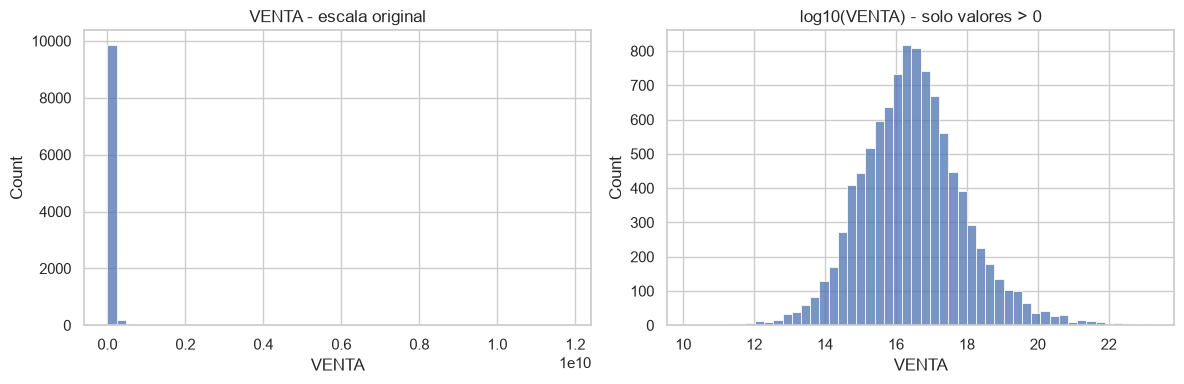

In [ ]:
# C10 — Distribución de VENTA: escala original frente a escala logarítmica
fig, axes = plt.subplots(1,2, figsize = (12,4))

sns.histplot(df["VENTA"], bins=50, ax=axes[0])
axes[0].set_title("VENTA - escala original")

sns.histplot(np.log1p(df.loc[df["VENTA"] > 0 , "VENTA"]), bins=50, ax=axes[1])
axes[1].set_title("log10(VENTA) - solo valores > 0")

plt.tight_layout()
plt.show()

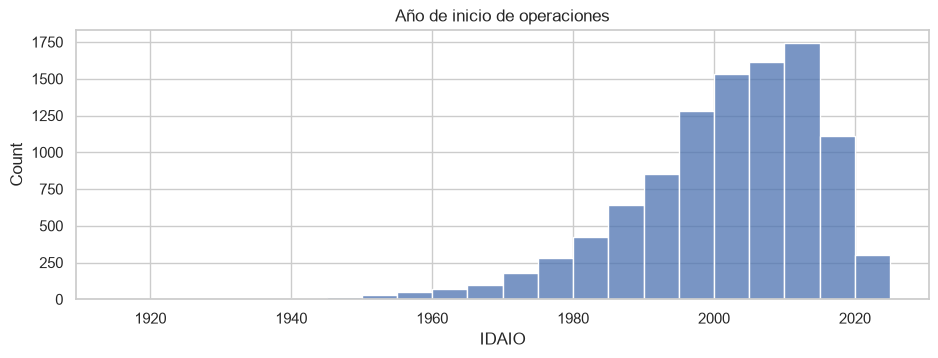

count   10,238.0
mean     2,001.1
std         13.5
min      1,918.0
25%      1,994.0
50%      2,003.0
75%      2,011.0
max      2,024.0
Name: IDAIO, dtype: float64

In [ ]:
# C11 — Distribución del año de inicio de operaciones
fig, ax = plt.subplots(figsize=(11, 3.5))
sns.histplot(df["IDAIO"], bins=list(range(1915, 2030, 5)), ax=ax)
ax.set_title("Año de inicio de operaciones")
plt.show()

df["IDAIO"].describe()

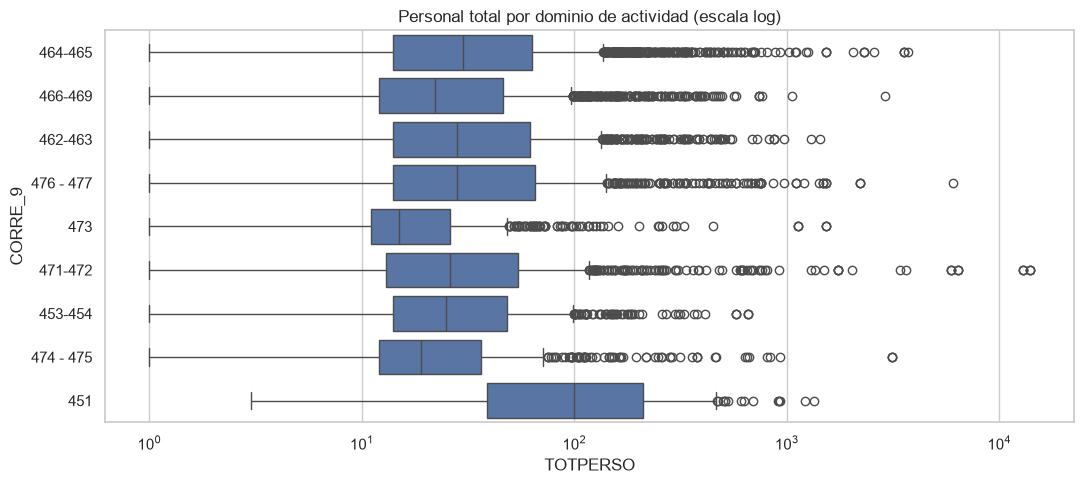

In [ ]:
# C12 — Personal total por dominio de actividad
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df[df["TOTPERSO"] > 0], x="TOTPERSO", y="CORRE_9", ax=ax,
            order=df["CORRE_9"].value_counts().index)
ax.set_xscale("log")
ax.set_title("Personal total por dominio de actividad (escala log)")
plt.tight_layout()
plt.show()

### Diagnóstico de problemas

In [132]:
# C13 — Valores faltantes
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "pct":   (df.isna().mean() * 100).round(3),
})
nulos[nulos["nulos"] > 0]

,nulos,pct
IDOJ1,2,0.0


In [133]:
# C14 — Duplicados: filas completas e identificador
print("Filas identicas:", df.duplicated().sum())
print("V1 repetidos   :", df["V1"].duplicated().sum())
print("V1 unicos      :", df["V1"].nunique(), "de", len(df))

Filas identicas: 0
V1 repetidos   : 0
V1 unicos      : 10238 de 10238


In [134]:
# C15 — Registros sin actividad económica
cifras = df.select_dtypes(include=np.number).columns.drop(["IDOJ1", "IDAIO"])
sin_actividad = (df[cifras] == 0).all(axis=1)

print("Registros con TODAS las cifras en cero:", sin_actividad.sum())
df.loc[sin_actividad, ["V1", "CORRELA_16", "IDAIO", "VENTA", "TOTPERSO"]].head()

Registros con TODAS las cifras en cero: 329


,V1,CORRELA_16,IDAIO,VENTA,TOTPERSO
28,1892140,466,2020,0.0,0.0
96,1892066,466,2018,0.0,0.0
119,1892039,466,2014,0.0,0.0
209,1891943,466,2015,0.0,0.0
216,1891935,465,2015,0.0,0.0


In [135]:
# C16 — Valores negativos en variables monetarias
negativos = (df[cifras] < 0).sum()
negativos[negativos > 0]

BRUTA      34
AGREGA    151
dtype: int64

In [136]:
# C17 — Verificación de las identidades contables del diccionario
id1 = np.isclose(df["BRUTA"] - df["CONSUI"], df["AGREGA"])
id2 = np.isclose(df["TOTMUJ"] + df["TOTHOM"], df["TOTPERSO"])

print(f"BRUTA - CONSUI = AGREGA    -> {id1.mean()*100:.2f} % de las filas")
print(f"TOTMUJ + TOTHOM = TOTPERSO -> {id2.mean()*100:.2f} % de las filas")

BRUTA - CONSUI = AGREGA    -> 100.00 % de las filas
TOTMUJ + TOTHOM = TOTPERSO -> 100.00 % de las filas


In [137]:
# C18 — Inconsistencias de formato y conteos de personal con decimales

print("Valores de CORRE_9:", [repr(v) for v in sorted(df["CORRE_9"].unique())])
print("Filas con TOTPERSO decimal:", (df["TOTPERSO"] % 1 != 0).sum())

df.loc[df["TOTPERSO"] % 1 != 0, ["V1", "TOTMUJ", "TOTHOM", "TOTPERSO"]].head()

Valores de CORRE_9: ["'451'", "'453-454'", "'462-463'", "'464-465'", "'466-469'", "'471-472'", "'473'", "'474 - 475'", "'476 - 477'"]
Filas con TOTPERSO decimal: 108


,V1,TOTMUJ,TOTHOM,TOTPERSO
2,3412456,6.4,8.8,15.2
3,3412455,9.6,13.2,22.8
4,3393256,3.6,8.8,12.4
5,3393255,5.4,13.2,18.6
6,3381856,4.0,2.8,6.8


In [138]:
# C19 — Códigos presentes en el CSV que no existen en el diccionario
ciiu = pd.read_excel(DIC_NACIONAL, sheet_name=2, header=8)

cod16 = set(ciiu.iloc[:, 4].dropna().astype(str))
cod9  = set(ciiu.iloc[:, 6].dropna().astype(str).str.replace(" ", "", regex=False))

huerfanos16 = set(df["CORRELA_16"]) - cod16
huerfanos9  = set(df["CORRE_9"].str.replace(" ", "", regex=False)) - cod9

print("CORRELA_16 sin descripcion:", huerfanos16)
print("CORRE_9 sin descripcion   :", huerfanos9)
print("Filas afectadas:", df["CORRELA_16"].isin(huerfanos16).sum())

CORRELA_16 sin descripcion: {'4771-4751'}
CORRE_9 sin descripcion   : set()
Filas afectadas: 328


In [139]:
# C20 — El archivo departamental: comprobar si cruza con el nacional
dep = pd.read_csv(EAC_DEPTO, sep=";", decimal=",", encoding="latin-1",
                  dtype={"V1": "string", "DEPTO": "string", "CORRELA_9": "string"})

print("Departamental:", dep.shape, "|", dep["V1"].nunique(), "empresas distintas")
print("V1 compartidos con el nacional:", len(set(dep["V1"]) & set(df["V1"])))
dep.head()

Departamental: (14995, 5) | 9902 empresas distintas
V1 compartidos con el nacional: 365


,V1,DEPTO,CORRELA_9,VENTA,Personal
0,994577,10,471-472,"4,212,573.0",8
1,994579,10,462-463,"5,421,934.0",12
2,994581,10,466-469,"13,437,761.0",9
3,994582,10,473,"11,727,195.0",18
4,994583,10,464-465,"12,834,252.0",10


## 1.4 Limpieza y transformación

In [140]:
# C21 — Crear la copia de trabajo
df_limpio = df.copy()
print("Punto de partida:", df_limpio.shape)

Punto de partida: (10238, 63)


In [141]:
# C22 — Eliminar los registros sin actividad económica
antes = len(df_limpio)
df_limpio = df_limpio.loc[~sin_actividad].copy()

print(f"Eliminados {antes - len(df_limpio)} registros sin actividad economica")
print("Dataset:", df_limpio.shape)

Eliminados 329 registros sin actividad economica
Dataset: (9909, 63)


In [142]:
# C23 — Tratar los valores faltantes de IDOJ1
print("Nulos en IDOJ1 antes:", df_limpio["IDOJ1"].isna().sum())

df_limpio["IDOJ1"] = df_limpio["IDOJ1"].fillna(-1).astype(int)

print("Nulos despues:", df_limpio["IDOJ1"].isna().sum())

Nulos en IDOJ1 antes: 2
Nulos despues: 0


In [144]:
# C24 — Recodificar IDOJ1 a etiquetas legibles
oj = pd.read_excel(DIC_NACIONAL, sheet_name=1, header=8)
oj.columns = ["codigo", "descripcion"]
oj = oj.dropna()
oj = oj[pd.to_numeric(oj["codigo"], errors="coerce").notna()]

mapa_oj = dict(zip(oj["codigo"].astype(int), oj["descripcion"].str.strip()))
mapa_oj[-1] = "Sin dato"

df_limpio["ORG_JURIDICA"] = df_limpio["IDOJ1"].map(mapa_oj)

print("Sin etiqueta:", df_limpio["ORG_JURIDICA"].isna().sum())
df_limpio["ORG_JURIDICA"].value_counts()

Sin etiqueta: 0


ORG_JURIDICA
Sociedad por Acciones Simplificada    6995
Persona natural                       1041
Sociedad anónima                       853
Sociedad limitada                      739
Organización de economía solidaria      67
Sociedad en comandita simple            63
Sucursal de sociedad extranjera         43
Entidades sin ánimo de lucro            38
Sociedad en comandita por acciones      29
Otras                                   19
Empresas unipersonales                  18
Sociedad de economía mixta               2
Sin dato                                 2
Name: count, dtype: int64

In [146]:
# C25 — Normalizar los códigos CIIU y añadir sus descripciones
df_limpio["CORRE_9"] = df_limpio["CORRE_9"].str.replace(" ", "", regex=False)

map16 = ciiu.iloc[:, [4, 5]].dropna().drop_duplicates().set_axis(["cod", "desc"], axis=1)
map9  = ciiu.iloc[:, [6, 7]].dropna().drop_duplicates().set_axis(["cod", "desc"], axis=1)
map9["cod"] = map9["cod"].astype(str).str.replace(" ", "", regex=False)

d16 = dict(zip(map16["cod"].astype(str), map16["desc"].str.strip()))
d9  = dict(zip(map9["cod"], map9["desc"].str.strip()))

# El codigo 4771-4751 aparece en el CSV pero no en el diccionario (ver C19).
d16["4771-4751"] = "Comercio al por menor de prendas de vestir y productos textiles"

df_limpio["ACTIVIDAD_16"] = df_limpio["CORRELA_16"].map(d16)
df_limpio["ACTIVIDAD_9"]  = df_limpio["CORRE_9"].map(d9)

print("Sin etiqueta 16:", df_limpio["ACTIVIDAD_16"].isna().sum(),
      "| sin etiqueta 9:", df_limpio["ACTIVIDAD_9"].isna().sum())

Sin etiqueta 16: 0 | sin etiqueta 9: 0


In [147]:
# C26 — Convertir las variables nominales a tipo category
for col in ["CORRELA_16", "CORRE_9", "ORG_JURIDICA", "ACTIVIDAD_16", "ACTIVIDAD_9"]:
    df_limpio[col] = df_limpio[col].astype("category")

df_limpio[["CORRELA_16", "ORG_JURIDICA", "ACTIVIDAD_9"]].dtypes

CORRELA_16      category
ORG_JURIDICA    category
ACTIVIDAD_9     category
dtype: object

In [148]:
# C27 — Construir las variables derivadas
df_limpio["ANTIGUEDAD"] = 2024 - df_limpio["IDAIO"]

df_limpio["TRAMO_PERSONAL"] = pd.cut(
    df_limpio["TOTPERSO"],
    bins=[0, 10, 50, 200, np.inf],
    labels=["Micro (1-10)", "Pequeña (11-50)", "Mediana (51-200)", "Grande (>200)"],
)

inf = [np.inf, -np.inf]
df_limpio["MARGEN"]       = (df_limpio["AGREGA"]  / df_limpio["VENTA"]).replace(inf, np.nan)
df_limpio["PART_MUJERES"] = (df_limpio["TOTMUJ"]  / df_limpio["TOTPERSO"]).replace(inf, np.nan)
df_limpio["REM_MEDIA"]    = (df_limpio["TOTREM"]  / df_limpio["PERREMUN"]).replace(inf, np.nan)

print(df_limpio["TRAMO_PERSONAL"].value_counts())
df_limpio[["ANTIGUEDAD", "MARGEN", "PART_MUJERES", "REM_MEDIA"]].isna().sum()

TRAMO_PERSONAL
Pequeña (11-50)     5602
Mediana (51-200)    2086
Micro (1-10)        1692
Grande (>200)        529
Name: count, dtype: int64


ANTIGUEDAD       0
MARGEN           0
PART_MUJERES     0
REM_MEDIA       88
dtype: int64

## 1.5 Resumen del dataset depurado

In [ ]:
# C28 — Comparación antes / después y resumen final
print(f"Original : {df.shape[0]:>6,} filas x {df.shape[1]} columnas")
print(f"Depurado : {df_limpio.shape[0]:>6,} filas x {df_limpio.shape[1]} columnas")
print(f"Eliminado: {df.shape[0]-df_limpio.shape[0]:>6,} filas "
      f"({(1-len(df_limpio)/len(df))*100:.1f} %)\n")

resumen_final = pd.DataFrame({
    "dtype":  df_limpio.dtypes.astype(str),
    "nulos":  df_limpio.isna().sum(),
    "unicos": df_limpio.nunique(),
})
resumen_final[resumen_final["nulos"] > 0]

Original : 10,238 filas x 63 columnas
Depurado :  9,909 filas x 71 columnas
Eliminado:    329 filas (3.2 %)



,dtype,nulos,unicos
REM_MEDIA,float64,88,9707


In [ ]:
# C29 — Guardar el dataset depurado
PROCESADOS.mkdir(parents=True, exist_ok=True)
salida = PROCESADOS / "eac_2024_limpio.csv"

df_limpio.to_csv(salida, index=False, encoding="utf-8")

print("Guardado:", salida)
print(f"{salida.stat().st_size / 1024 / 1024:.1f} MB")

Guardado: d:\DOCUMENTS\StivenMelo\EAN-university\1.First Semester\DataXperience\EncuestaAnualdeComercio-EAC-2024\datos\procesados\eac_2024_limpio.csv
7.2 MB


---
# Módulo 2 — _(pendiente de completar)_

---
# Módulo 3 — _(pendiente de completar)_

---
## Conclusiones

_(Qué aprendimos y cómo aplicaríamos estas herramientas profesionalmente.)_

1.
2.
3.